Cell 1 — Markdown

# RetailOps AI
## Notebook 01 — Data and Environment Setup

### Purpose
This notebook prepares and validates the retail environment used by RetailOps AI.

The project is built on the public τ²-Bench retail domain, which provides:
- structured retail users, orders, products, and payment data,
- domain policies,
- tool-oriented customer-service tasks,
- predefined task splits for evaluation.

### Goals
By the end of this notebook, we will:

1. Install and verify the required environment.
2. Load the τ²-Bench Retail domain.
3. Inspect the database structure and data quality.
4. Inspect the official retail policy.
5. Examine the available benchmark tasks and task splits.
6. Verify that development and evaluation resources remain separated.
7. Export reusable metadata for later notebooks.

> This notebook does not run the AI agent or modify the retail database.
> It is intentionally read-only to preserve evaluation integrity.

Cell 2 — Install Dependencies

In [1]:
!pip -q install uv pandas matplotlib pydantic

In [2]:
print("core dependencies installed.")

core dependencies installed.


Cell 3 — Clone τ²-Bench

In [3]:
from pathlib import Path
import os

REPO_DIR = Path("/content/tau2-bench")

if not REPO_DIR.exists():
    !git clone -q https://github.com/sierra-research/tau2-bench.git /content/tau2-bench

os.chdir(REPO_DIR)

print(" τ²-Bench repository ready.")
print("Repository:", REPO_DIR)

 τ²-Bench repository ready.
Repository: /content/tau2-bench


Cell 4 — Pin the Repository Revision

In [4]:
import subprocess

commit_sha = subprocess.check_output(
    ["git", "rev-parse", "HEAD"],
    text=True
).strip()

print("τ²-Bench commit:", commit_sha)

τ²-Bench commit: 122e2432b82d740e8f313f46f0a071729c404f39


Cell 5 — Install τ²-Bench Environment

In [5]:
!uv sync -q

In [6]:
print(" τ²-Bench environment synchronized.")

 τ²-Bench environment synchronized.


Cell 6 — Define Retail Paths

In [7]:
from pathlib import Path

RETAIL_DIR = REPO_DIR / "data" / "tau2" / "domains" / "retail"

DB_PATH = RETAIL_DIR / "db.json"
POLICY_PATH = RETAIL_DIR / "policy.md"
TASKS_PATH = RETAIL_DIR / "tasks.json"
SPLITS_PATH = RETAIL_DIR / "split_tasks.json"

required_files = {
    "database": DB_PATH,
    "policy": POLICY_PATH,
    "tasks": TASKS_PATH,
    "task splits": SPLITS_PATH,
}

for name, path in required_files.items():
    print(f"{name:12} → {'' if path.exists() else ''} {path.name}")

assert all(path.exists() for path in required_files.values())

print("\n All required Retail domain files are available.")

database     →  db.json
policy       →  policy.md
tasks        →  tasks.json
task splits  →  split_tasks.json

 All required Retail domain files are available.


Cell 7 — Load Database

In [8]:
import json

with open(DB_PATH, "r", encoding="utf-8") as f:
    retail_db = json.load(f)

print(retail_db.keys())

dict_keys(['products', 'users', 'orders'])


Cell 8 — Dataset Size Summary

In [9]:
num_products = len(retail_db["products"])
num_users = len(retail_db["users"])
num_orders = len(retail_db["orders"])

num_variants = sum(
    len(product.get("variants", {}))
    for product in retail_db["products"].values()
)

dataset_summary = {
    "Products": num_products,
    "Product variants": num_variants,
    "Users": num_users,
    "Orders": num_orders,
}

dataset_summary

{'Products': 50, 'Product variants': 591, 'Users': 500, 'Orders': 1000}

Cell 9 — Visual Summary

In [10]:
import pandas as pd

summary_df = pd.DataFrame(
    dataset_summary.items(),
    columns=["Entity", "Count"]
)

summary_df

,Entity,Count
0,Products,50
1,Product variants,591
2,Users,500
3,Orders,1000


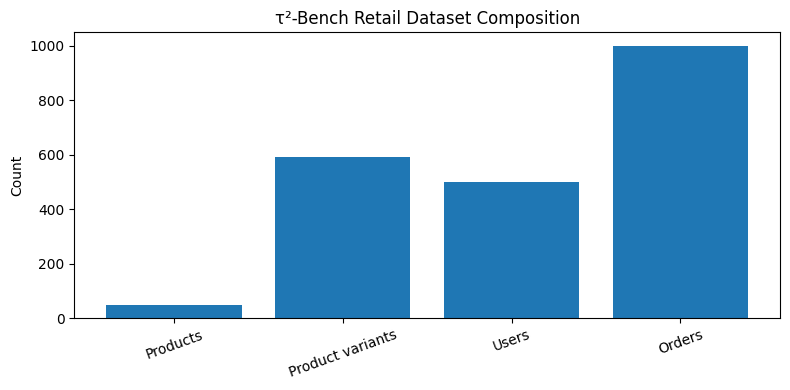

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.bar(summary_df["Entity"], summary_df["Count"])
plt.title("τ²-Bench Retail Dataset Composition")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Cell 10 — Inspect User Schema Safely

In [12]:
first_user_id, first_user = next(iter(retail_db["users"].items()))

safe_user_preview = {
    "user_id": first_user_id,
    "name_fields_present": list(first_user.get("name", {}).keys()),
    "payment_method_count": len(first_user.get("payment_methods", {})),
    "order_count": len(first_user.get("orders", [])),
}

safe_user_preview

{'user_id': 'noah_brown_6181',
 'name_fields_present': ['first_name', 'last_name'],
 'payment_method_count': 2,
 'order_count': 1}

Cell 11 — Inspect Example Order

In [13]:
first_order_id, first_order = next(iter(retail_db["orders"].items()))

order_preview = {
    "order_id": first_order_id,
    "status": first_order.get("status"),
    "number_of_items": len(first_order.get("items", [])),
    "payment_records": len(first_order.get("payment_history", [])),
    "fulfillments": len(first_order.get("fulfillments", [])),
}

order_preview

{'order_id': '#W2611340',
 'status': 'processed',
 'number_of_items': 2,
 'payment_records': 1,
 'fulfillments': 1}

Cell 12 — Order Status Distribution

In [14]:
from collections import Counter

order_status_counts = Counter(
    order["status"]
    for order in retail_db["orders"].values()
)

status_df = (
    pd.DataFrame(
        order_status_counts.items(),
        columns=["Status", "Count"]
    )
    .sort_values("Count", ascending=False)
    .reset_index(drop=True)
)

status_df

,Status,Count
0,pending,423
1,delivered,373
2,processed,102
3,cancelled,102


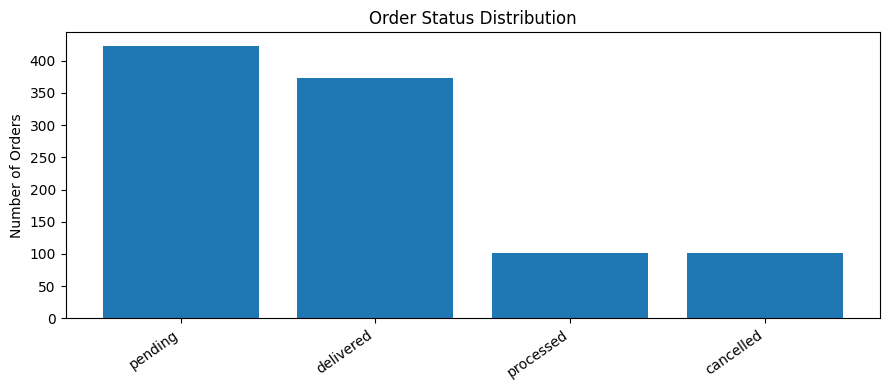

In [15]:
plt.figure(figsize=(9, 4))
plt.bar(status_df["Status"], status_df["Count"])
plt.title("Order Status Distribution")
plt.ylabel("Number of Orders")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Cell 13 — Product Availability

In [16]:
variant_records = []

for product_id, product in retail_db["products"].items():
    for variant_id, variant in product.get("variants", {}).items():
        variant_records.append({
            "product_id": product_id,
            "variant_id": variant_id,
            "available": variant.get("available"),
            "price": variant.get("price"),
        })

variants_df = pd.DataFrame(variant_records)

variants_df.head()

,product_id,variant_id,available,price
0,9523456873,9612497925,True,50.88
1,9523456873,8124970213,True,49.67
2,9523456873,9354168549,True,46.85
3,9523456873,5253880258,True,49.52
4,9523456873,1176194968,True,52.88


In [17]:
availability_summary = (
    variants_df["available"]
    .value_counts(dropna=False)
    .rename_axis("Available")
    .reset_index(name="Count")
)

availability_summary

,Available,Count
0,True,379
1,False,212


Cell 14 — Price Sanity Checks

In [18]:
price_summary = variants_df["price"].describe()

price_summary

,price
count,591.000000
mean,546.898697
std,754.345715
min,28.140000
25%,180.380000
50%,256.730000
75%,503.670000
max,3289.460000


In [19]:
assert (variants_df["price"] >= 0).all()

print(" No negative product prices detected.")

 No negative product prices detected.


Cell 15 — Referential Integrity

In [20]:
missing_order_users = []

for order_id, order in retail_db["orders"].items():
    if order["user_id"] not in retail_db["users"]:
        missing_order_users.append(order_id)

print("Orders with missing users:", len(missing_order_users))

assert len(missing_order_users) == 0

print("Every order references an existing user.")

Orders with missing users: 0
Every order references an existing user.


Cell 16 — Product Reference Integrity

In [21]:
missing_products = []

for order_id, order in retail_db["orders"].items():
    for item in order.get("items", []):
        if item["product_id"] not in retail_db["products"]:
            missing_products.append(
                (order_id, item["product_id"])
            )

print("Missing product references:", len(missing_products))

assert len(missing_products) == 0

print("✅ All order items reference valid products.")

Missing product references: 0
✅ All order items reference valid products.


Cell 17 — Load Retail Policy

In [22]:
policy_text = POLICY_PATH.read_text(encoding="utf-8")

print(policy_text[:3000])

# Retail agent policy

As a retail agent, you can help users:

- **cancel or modify pending orders**
- **return or exchange delivered orders**
- **modify their default user address**
- **provide information about their own profile, orders, and related products**

At the beginning of the conversation, you have to authenticate the user identity by locating their user id via email, or via name + zip code. This has to be done even when the user already provides the user id.

Once the user has been authenticated, you can provide the user with information about order, product, profile information, e.g. help the user look up order id.

You can only help one user per conversation (but you can handle multiple requests from the same user), and must deny any requests for tasks related to any other user.

Before taking any action that updates the database (cancel, modify, return, exchange), you must list the action details and obtain explicit user confirmation (yes) to proceed.

You should not mak

Cell 18 — Policy Metadata

In [23]:
policy_lines = [
    line.strip()
    for line in policy_text.splitlines()
    if line.strip()
]

print("Policy characters:", len(policy_text))
print("Non-empty lines:", len(policy_lines))

Policy characters: 6699
Non-empty lines: 77


Cell 19 — Load Benchmark Tasks

In [24]:
with open(TASKS_PATH, "r", encoding="utf-8") as f:
    retail_tasks = json.load(f)

print("Number of retail tasks:", len(retail_tasks))

Number of retail tasks: 114


Cell 20 — Inspect Task Schema

In [25]:
first_task = retail_tasks[0]

print(first_task.keys())

dict_keys(['id', 'description', 'user_scenario', 'initial_state', 'evaluation_criteria'])


In [26]:
from pprint import pprint

pprint(first_task)

{'description': {'notes': None, 'purpose': None, 'relevant_policies': None},
 'evaluation_criteria': {'actions': [{'action_id': '0_0',
                                      'arguments': {'first_name': 'Yusuf',
                                                    'last_name': 'Rossi',
                                                    'zip': '19122'},
                                      'info': None,
                                      'name': 'find_user_id_by_name_zip'},
                                     {'action_id': '0_1',
                                      'arguments': {'order_id': '#W2378156'},
                                      'info': None,
                                      'name': 'get_order_details'},
                                     {'action_id': '0_2',
                                      'arguments': {'product_id': '1656367028'},
                                      'info': None,
                                      'name': 'get_product_details'},
   

Cell 21 — Load Official Task Splits

In [27]:
with open(SPLITS_PATH, "r", encoding="utf-8") as f:
    task_splits = json.load(f)

task_splits.keys()

dict_keys(['train', 'test', 'base'])

1. Cell 22 — Train/Test Leakage Check

In [28]:
train_ids = set(task_splits["train"])
test_ids = set(task_splits["test"])
base_ids = set(task_splits["base"])

train_test_overlap = train_ids.intersection(test_ids)

print("Train tasks:", len(train_ids))
print("Test tasks:", len(test_ids))
print("Train/Test overlap:", len(train_test_overlap))

assert len(train_test_overlap) == 0, \
    f"Data leakage risk: {len(train_test_overlap)} tasks appear in both train and test."

assert train_ids.union(test_ids) == base_ids, \
    "Train + test task IDs do not exactly reconstruct the base task set."

print(" Train and test tasks are disjoint.")
print(" Train + test reconstruct the complete base task set.")

Train tasks: 74
Test tasks: 40
Train/Test overlap: 0
 Train and test tasks are disjoint.
 Train + test reconstruct the complete base task set.


In [29]:
split_summary = {
    split_name: len(task_ids)
    for split_name, task_ids in task_splits.items()
}

split_summary

{'train': 74, 'test': 40, 'base': 114}

Cell 23 — Define Our Project Evaluation Rule

## Evaluation Integrity Rule

RetailOps AI will follow the following evaluation protocol:

- The retail database and public policy are part of the agent environment.
- Development examples may be used to debug tools and prompts.
- Final evaluation tasks will be frozen before the final A/B experiment.
- The same frozen tasks will be used for Configuration A and Configuration B.
- Expected outcomes from held-out evaluation tasks will not be inserted into prompts, retrieval context, or manually encoded rules.
- Failed evaluation examples will be used only for error analysis after the evaluation run.
- Final metrics will be reported exactly as observed, without removing difficult cases.

This separation is intended to reduce evaluation leakage and make the A/B comparison reproducible.

Cell 24 — Save Project Metadata

In [30]:
PROJECT_DIR = Path("/content/RetailOps_AI")
ARTIFACT_DIR = PROJECT_DIR / "artifacts"

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

project_metadata = {
    "tau2_commit": commit_sha,
    "retail_database": {
        "products": num_products,
        "variants": num_variants,
        "users": num_users,
        "orders": num_orders,
    },
    "retail_tasks": len(retail_tasks),
    "task_splits": split_summary,
}

metadata_path = ARTIFACT_DIR / "data_environment_summary.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(
        project_metadata,
        f,
        indent=2,
        ensure_ascii=False
    )

print(" Metadata saved to:", metadata_path)

 Metadata saved to: /content/RetailOps_AI/artifacts/data_environment_summary.json


Cell 25 — Save Policy Snapshot

In [31]:
policy_snapshot_path = ARTIFACT_DIR / "retail_policy_snapshot.md"

policy_snapshot_path.write_text(
    policy_text,
    encoding="utf-8"
)

print(" Policy snapshot saved.")

 Policy snapshot saved.


Cell 26 — Final Validation

In [32]:
checks = {
    "Retail database loaded": bool(retail_db),
    "Products available": num_products > 0,
    "Users available": num_users > 0,
    "Orders available": num_orders > 0,
    "Policy loaded": len(policy_text) > 0,
    "Tasks loaded": len(retail_tasks) > 0,
    "Task splits loaded": len(task_splits) > 0,
    "No missing order users": len(missing_order_users) == 0,
    "No missing product references": len(missing_products) == 0,
}

validation_df = pd.DataFrame(
    [
        {
            "Check": name,
            "Status": "PASS" if passed else "FAIL"
        }
        for name, passed in checks.items()
    ]
)

validation_df

,Check,Status
0,Retail database loaded,PASS
1,Products available,PASS
2,Users available,PASS
3,Orders available,PASS
4,Policy loaded,PASS
5,Tasks loaded,PASS
6,Task splits loaded,PASS
7,No missing order users,PASS
8,No missing product references,PASS


In [33]:
assert all(checks.values())

print("Notebook 01 validation passed.")

Notebook 01 validation passed.


## Notebook 01 Conclusion

The τ²-Bench Retail environment was successfully loaded and validated.

The notebook confirmed:

- a structured retail database containing users, products, variants, and orders,
- valid relationships between orders, users, and products,
- multiple operational order states,
- an official retail policy,
- public benchmark tasks and task splits,
- a fixed τ²-Bench repository revision for reproducibility,
- and a documented evaluation-integrity rule.

No agent execution or database write operation was performed in this notebook.

### Next
Notebook 02 will focus on:

**Policy Context and Retrieval Engineering**

It will evaluate how the agent should access the retail policy and compare retrieval/context strategies before they are integrated into the final agent harness.